# 03 · Exploratory data analysis

What the cleaned data looks like, for the report and to explain the modelling choices.

**The rule:** the analyses of the petition **text** (lengths, distinctive words, duplicate similarity) and of the
moderation lag (sections 4–7) use **train + validation only**. Two sections use every petition: the class counts
(sections 2–3), which are already in the locked tables of 02 and 04, and the data-quality table (section 8), which
recounts the dataset-wide checks of 02 and the Milestone-1 audit. Neither feeds a model choice: every setting was
frozen in 08 before this notebook was written.

**Input** (in `data/processed/`): `petitions.parquet`, `out_of_scope.parquet`, `gold_pairs.parquet`, `splits.parquet`
and the MiniLM vectors.

**Output:** figures `reports/figures/eda_*.png`, tables `reports/eda_*.csv`.

Steps: 1 load → 2 classes per Parliament → 3 classes over time → 4 text length → 5 distinctive words →
6 moderation lag → 7 duplicates and their links → 8 data-quality table. Runs on the laptop in about 2 minutes.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

ROOT = Path.cwd().parent                      # this notebook runs inside notebooks/
sys.path.insert(0, str(ROOT / "src"))
from preprocess import CLASSES
from splits import TRAIN_END, VAL_END

DATA, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(exist_ok=True)
SEED = 42

# One fixed colour per class, in CLASSES order (validated categorical palette)
COLOURS = dict(zip(CLASSES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "text.color": INK,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 110,
                     "savefig.dpi": 200, "savefig.bbox": "tight"})

## 1. Load

In [2]:
petitions = pd.read_parquet(DATA / "petitions.parquet")
petitions = petitions.merge(pd.read_parquet(DATA / "splits.parquet"), on="id", validate="one_to_one")
out_of_scope = pd.read_parquet(DATA / "out_of_scope.parquet")
gold = pd.read_parquet(DATA / "gold_pairs.parquet")
seen = petitions[petitions["split"].isin(["train", "val"])]      # the part the text analyses may look at
assert (len(petitions), len(out_of_scope), len(seen)) == (127_191, 886, 120_447)
print(f"{len(petitions):,} petitions in scope, {len(out_of_scope):,} out of scope; {len(seen):,} in train + validation")

127,191 petitions in scope, 886 out of scope; 120,447 in train + validation


## 2. Classes per Parliament

The share of each outcome in each Parliament, for the 127,191 in-scope petitions (the 886 dropped ones are not
counted, so the totals are a little below the Parliament table of Milestone 1).

In [3]:
PARLIAMENTS = ["2015-17", "2017-19", "2019-24", "current"]
counts = pd.crosstab(petitions["label"], petitions["source"]).reindex(index=CLASSES, columns=PARLIAMENTS)
shares = (counts / counts.sum() * 100).round(1)
table = counts.astype(str) + " (" + shares.astype(str) + "%)"
table.loc["total"] = counts.sum().map("{:,}".format)
table.to_csv(REPORTS / "eda_classes_per_parliament.csv")
table

source,2015-17,2017-19,2019-24,current
label,,,,
published,10950 (34.8%),8152 (29.2%),13752 (26.6%),7527 (46.5%)
duplicate,11789 (37.5%),9125 (32.7%),19198 (37.2%),4771 (29.5%)
irrelevant,4634 (14.7%),4599 (16.5%),8824 (17.1%),1290 (8.0%)
no-action,3375 (10.7%),5063 (18.1%),6494 (12.6%),1515 (9.4%)
honours,682 (2.2%),963 (3.5%),1212 (2.3%),178 (1.1%)
already-happening,0 (0.0%),0 (0.0%),2104 (4.1%),340 (2.1%)
local,0 (0.0%),0 (0.0%),86 (0.2%),568 (3.5%)
total,"31,430","27,902","51,670","16,189"


## 3. Classes over time

Each bar is one quarter (by decision time), split into the share of each outcome. Quarters with fewer than 300
decisions (the gaps between Parliaments) are left out, so the bars are not evenly spaced in time; each year is
labelled at its first quarter. The dashed lines mark the start of validation and test.

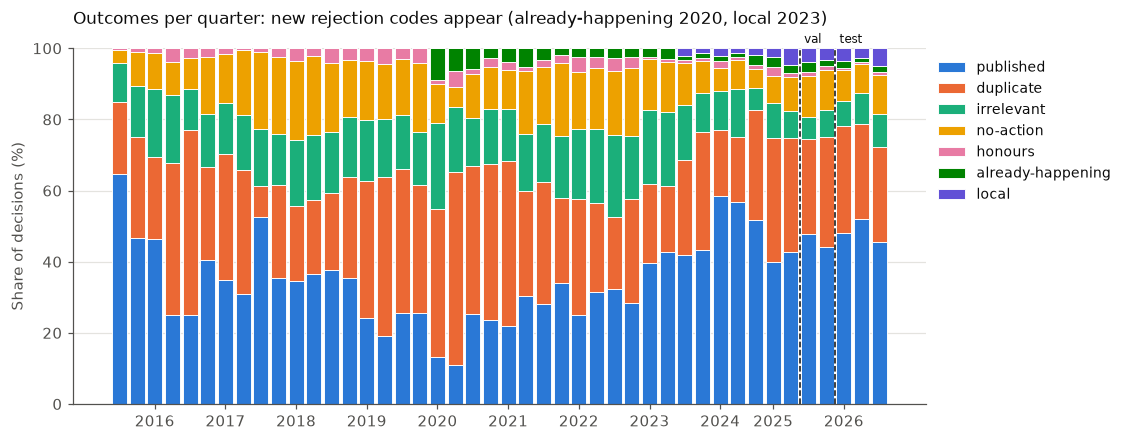

44 quarters shown; quarters without enough decisions (between Parliaments): ['2024Q3']


In [4]:
timed = petitions[petitions["split"] != "excluded"].copy()
timed["quarter"] = timed["decision_time"].dt.tz_convert(None).dt.to_period("Q")
by_quarter = pd.crosstab(timed["quarter"], timed["label"]).reindex(columns=CLASSES, fill_value=0)
by_quarter = by_quarter[by_quarter.sum(axis=1) >= 300]
quarter_shares = by_quarter.div(by_quarter.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(quarter_shares))
bottom = np.zeros(len(quarter_shares))
for c in CLASSES:
    ax.bar(x, quarter_shares[c], bottom=bottom, width=0.86, color=COLOURS[c], label=c, edgecolor="white", linewidth=0.6)
    bottom += quarter_shares[c].to_numpy()
labels = [str(q) for q in quarter_shares.index]
first_quarters = [i for i, q in enumerate(quarter_shares.index) if q.quarter == 1]
ax.set_xticks(first_quarters, [str(quarter_shares.index[i].year) for i in first_quarters])
for start, name in [(pd.Period(TRAIN_END.tz_convert(None), "Q"), "val"), (pd.Period(VAL_END.tz_convert(None), "Q"), "test")]:
    position = labels.index(str(start)) - 0.5
    ax.axvline(position, color=INK, linestyle="--", linewidth=1)
    ax.text(position + 0.25, 101.5, name, color=INK, fontsize=8)
ax.set_ylim(0, 100)
ax.set_ylabel("Share of decisions (%)")
ax.set_title("Outcomes per quarter: new rejection codes appear (already-happening 2020, local 2023)", loc="left", fontsize=11, pad=16)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "eda_classes_over_time.png")
plt.show()
missing = pd.period_range(timed["quarter"].min(), timed["quarter"].max(), freq="Q").difference(by_quarter.index)
print(f"{len(quarter_shares)} quarters shown; quarters without enough decisions (between Parliaments): {[str(q) for q in missing]}")

In [5]:
# When each outcome was first and last used (all in-scope decisions, plus the dropped codes)
everyone = pd.concat([petitions[["label", "decision_time"]], out_of_scope[["label", "decision_time"]]])
first_last = everyone.groupby("label")["decision_time"].agg(["count", "min", "max"])
first_last[["min", "max"]] = first_last[["min", "max"]].apply(lambda s: s.dt.strftime("%Y-%m-%d"))
first_last.columns = ["decisions", "first", "last"]
first_last.reindex(CLASSES + ["fake-name", "operational", "foi"])

,decisions,first,last
label,,,
published,40381,2015-07-20,2026-09-25
duplicate,44883,2015-07-21,2026-09-25
irrelevant,19347,2015-07-21,2026-09-25
no-action,16447,2015-08-03,2026-09-25
honours,3035,2015-07-24,2026-09-15
already-happening,2444,2020-03-27,2026-09-25
local,654,2023-07-20,2026-09-24
fake-name,829,2015-08-11,2025-03-14
operational,30,2023-09-08,2026-08-06


## 4. Text length (train + validation)

Words are runs of letters and digits ("don't" counts once); the " . " that joins the three fields is not a word.

In [6]:
words = seen["text"].str.count(r"[A-Za-z0-9]+(?:'[A-Za-z]+)?")
length = words.groupby(seen["label"]).describe()[["count", "25%", "50%", "75%", "max"]].reindex(CLASSES)
length.columns = ["petitions", "q1 words", "median words", "q3 words", "max words"]
length["no additional details (%)"] = ((seen["additional_details"].fillna("") == "").groupby(seen["label"]).mean().reindex(CLASSES) * 100).round(1)
length = length.astype({"petitions": int}).round(1)
length.to_csv(REPORTS / "eda_text_length.csv")
print(f"all: median {words.median():.0f} words; {(seen['additional_details'].fillna('') == '').mean():.1%} have no additional details")
length

all: median 103 words; 21.6% have no additional details


,petitions,q1 words,median words,q3 words,max words,no additional details (%)
label,,,,,,
published,37029,71.0,113.0,136.0,217.0,17.3
duplicate,43069,59.0,95.0,132.0,226.0,24.9
irrelevant,18791,58.0,95.0,133.0,214.0,24.0
no-action,15818,62.0,105.0,136.0,220.0,20.2
honours,2999,43.0,63.0,102.5,204.0,33.9
already-happening,2328,75.0,111.0,135.0,214.0,5.8
local,413,78.0,111.0,131.0,170.0,4.4


## 5. Distinctive words per class (train + validation)

For each class: the words and word pairs that appear in a much larger share of its petitions than of the others
("lift" = share in the class ÷ share elsewhere; 1 is added to the count elsewhere, so a term that never appears
outside the class does not divide by zero). Only terms in at least 50 petitions overall and 30 of the class count,
so rare oddities do not dominate. Common English words are removed, so a pair such as "election soon" can stand for
"an election as soon as possible".

In [7]:
vectorizer = CountVectorizer(binary=True, ngram_range=(1, 2), min_df=50, stop_words="english", lowercase=True)
present = vectorizer.fit_transform(seen["text"])
terms = vectorizer.get_feature_names_out()
labels = seen["label"].to_numpy()
distinctive = {}
for c in CLASSES:
    inside = labels == c
    in_class = np.asarray(present[inside].sum(axis=0)).ravel()
    elsewhere = np.asarray(present[~inside].sum(axis=0)).ravel()
    lift = (in_class / inside.sum()) / ((elsewhere + 1) / (~inside).sum())
    lift[in_class < 30] = 0
    best = np.argsort(-lift)[:10]
    distinctive[c] = [f"{terms[i]} ({lift[i]:.0f}x)" for i in best]
distinctive = pd.DataFrame(distinctive)
distinctive.to_csv(REPORTS / "eda_distinctive_words.csv", index=False)
print(f"{len(terms):,} terms")
distinctive

14,313 terms


,published,duplicate,irrelevant,no-action,honours,already-happening,local
0,fund increased (59x),election soon (97x),england manager (143x),stop discrimination (7x),knighthood (682x),employed 80 (216x),town (15x)
1,review consider (39x),stop 2nd (93x),eurovision (64x),sharia law (6x),knighted (653x),80 income (99x),residents (13x)
2,fund research (38x),stop second (76x),congestion charge (39x),magna (6x),knighthood captain (439x),million self (86x),council (12x)
3,think current (36x),say second (48x),second dose (36x),magna carta (6x),knight (413x),european super (68x),park (11x)
4,specific offence (26x),inquiry grooming (31x),igcse (30x),carta (6x),moore knighthood (321x),super league (64x),area (11x)
5,require local (23x),ignore petition (30x),expenses mps (26x),sharia (5x),confidence boris (239x),algorithm (58x),city (10x)
6,specific criminal (22x),visit united (28x),fa cup (25x),indigenous (4x),tom moore (221x),pay self (46x),traffic (9x)
7,fund free (21x),petition second (27x),mp pay (21x),stop illegal (4x),captain tom (158x),pay 80 (40x),community (8x)
8,awareness campaign (19x),allow donald (25x),claim expenses (18x),cms (4x),honours list (147x),level results (38x),building (8x)
9,government require (16x),50 immediately (24x),uber (17x),overhaul (4x),peerage (141x),downgraded (35x),local (7x)


## 6. Moderation lag (train + validation)

Days from the petition's creation to the moderator's decision (publication or rejection).

In [8]:
lag_days = (seen["decision_time"] - seen["created_at"]).dt.total_seconds() / 86400
lag = lag_days.groupby(seen["label"]).describe(percentiles=[0.25, 0.5, 0.75, 0.9])[["25%", "50%", "75%", "90%"]].reindex(CLASSES).round(1)
lag.columns = ["q1 days", "median days", "q3 days", "90% within days"]
lag["over 90 days"] = (lag_days > 90).groupby(seen["label"]).sum().reindex(CLASSES)
by_year = lag_days.groupby(seen["decision_time"].dt.year).median().round(1)
lag.to_csv(REPORTS / "eda_moderation_lag.csv")
print("median lag per decision year:", by_year.to_dict())
lag

median lag per decision year: {2015: 3.1, 2016: 4.9, 2017: 6.7, 2018: 6.7, 2019: 9.9, 2020: 14.4, 2021: 6.5, 2022: 4.8, 2023: 5.3, 2024: 14.6, 2025: 34.0}


,q1 days,median days,q3 days,90% within days,over 90 days
label,,,,,
published,4.9,8.1,20.1,42.5,400
duplicate,4.5,6.9,13.9,32.7,119
irrelevant,4.0,6.6,12.7,33.6,88
no-action,5.1,7.5,16.7,35.8,105
honours,3.1,5.8,10.6,21.5,10
already-happening,5.9,9.7,30.7,48.1,4
local,12.0,20.1,30.1,47.6,0


## 7. Duplicates and their links (train + validation)

The gold pairs link a rejected duplicate to the open petition(s) the moderator named. How similar are they? The
MiniLM cosine of each gold pair is compared with random pairs of published petitions.

58,956 gold pairs for 42,899 duplicates in train + validation; 15.3% have several correct petitions (max 17)


MiniLM cosine: gold pairs median 0.66 (11.1% below 0.5); random published pairs median 0.15


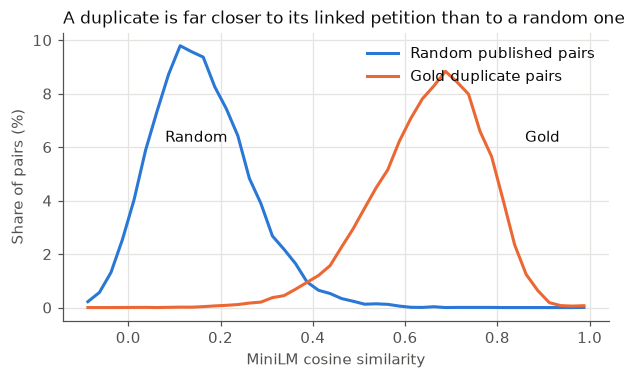

In [9]:
queries = gold[gold["query_id"].isin(seen["id"])]
links_per_query = queries.groupby("query_id").size()
print(f"{len(queries):,} gold pairs for {links_per_query.size:,} duplicates in train + validation; "
      f"{(links_per_query > 1).mean():.1%} have several correct petitions (max {links_per_query.max()})")

ids = np.load(DATA / "embeddings" / "minilm_ids.npy")
vectors = np.load(DATA / "embeddings" / "minilm_vectors.npy", mmap_mode="r")
row = pd.Series(np.arange(len(ids)), index=ids)
a = np.asarray(vectors[row.loc[queries["query_id"]].to_numpy()])
b = np.asarray(vectors[row.loc[queries["target_id"]].to_numpy()])
gold_cosine = np.sum(a * b, axis=1)
published_ids = petitions.loc[petitions["label"] == "published", "id"].to_numpy()
rng = np.random.default_rng(SEED)
r1, r2 = rng.choice(published_ids, 20_000), rng.choice(published_ids, 20_000)
random_cosine = np.sum(np.asarray(vectors[row.loc[r1].to_numpy()]) * np.asarray(vectors[row.loc[r2].to_numpy()]), axis=1)
print(f"MiniLM cosine: gold pairs median {np.median(gold_cosine):.2f} ({(gold_cosine < 0.5).mean():.1%} below 0.5); "
      f"random published pairs median {np.median(random_cosine):.2f}")

bins = np.linspace(-0.1, 1.0, 45)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for values, colour, name in [(random_cosine, "#2a78d6", "Random published pairs"), (gold_cosine, "#eb6834", "Gold duplicate pairs")]:
    share = np.histogram(values, bins=bins)[0] / len(values) * 100
    ax.plot((bins[:-1] + bins[1:]) / 2, share, color=colour, linewidth=2, label=name)
ax.text(0.08, 6.2, "Random", color=INK)
ax.text(0.86, 6.2, "Gold", color=INK)
ax.set_xlabel("MiniLM cosine similarity")
ax.set_ylabel("Share of pairs (%)")
ax.set_title("A duplicate is far closer to its linked petition than to a random one", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right")
fig.savefig(FIGURES / "eda_gold_pair_similarity.png")
plt.show()

## 8. Data-quality table

Dataset-wide checks (all 128,077 petitions or all 127,191 in scope, as noted), recomputed from the cleaned files. The
Milestone-1 audit counted some of them on the raw data with its own rules, so a few numbers differ slightly; its
manual check of 25 low-similarity links (1 wrong, 2 doubtful) is not repeated here.

In [10]:
both = pd.concat([petitions, out_of_scope], ignore_index=True)      # all 128,077 petitions of the snapshot
duplicates = (petitions["label"] == "duplicate").sum()
outcomes = petitions.groupby("text")["label"].agg(lambda s: frozenset(s))
several = outcomes[outcomes.map(len) > 1]
explained = several.map(lambda s: s <= {"published", "duplicate"})    # only these two outcomes: timing can explain it
lag_all = (both["decision_time"] - both["created_at"]).dt.total_seconds() / 86400
rejected = both["label"] != "published"
quality = pd.DataFrame([
    ("petitions in the snapshot", len(both), "25 Sep 2026, SHA-256 checked in 02"),
    ("dropped: fake-name / operational / foi", len(out_of_scope), str(out_of_scope["label"].value_counts().to_dict())),
    ("excluded: decided after 31 Aug 2026", (petitions["split"] == "excluded").sum(), "not in train / validation / test"),
    ("published, then rejected (counted as rejected)", (both["opened_at"].notna() & rejected).sum(), "never a pool member"),
    ("texts with a link replaced by [URL]", both["text"].str.contains("[URL]", regex=False).sum(), "all 128,077; links carry no meaning for the models"),
    ("no additional details (in scope)", (petitions["additional_details"].fillna("") == "").sum(), "the field is optional"),
    ("likely not English (in scope)", petitions["likely_non_english"].sum(), "kept, reported"),
    ("duplicates without a valid link", duplicates - gold["query_id"].nunique(), "kept for classification, not for retrieval"),
    ("duplicates with several valid links", (gold.groupby("query_id").size() > 1).sum(), "any of them counts as correct"),
    ("identical texts, different outcomes: only published and duplicate (groups)", explained.sum(), "in scope; a text is a duplicate while a similar petition is open, and can be published at another time"),
    ("identical texts, different outcomes: other mixes (groups)", (~explained).sum(), "in scope; unexplained label noise"),
    ("rejected more than 90 days after creation", (rejected & (lag_all > 90)).sum(), f"all 128,077; M1 audit: 348; longest {lag_all.max() / 365:.1f} years (#313513)"),
    ("published more than 90 days after creation", (~rejected & (lag_all > 90)).sum(), "all 128,077; slow publications"),
], columns=["check", "count", "note"])
quality.to_csv(REPORTS / "eda_data_quality.csv", index=False)
quality

,check,count,note
0,petitions in the snapshot,128077,"25 Sep 2026, SHA-256 checked in 02"
1,dropped: fake-name / operational / foi,886,"{'fake-name': 829, 'operational': 30, 'foi': 27}"
2,excluded: decided after 31 Aug 2026,562,not in train / validation / test
3,"published, then rejected (counted as rejected)",49,never a pool member
4,texts with a link replaced by [URL],6504,"all 128,077; links carry no meaning for the mo..."
5,no additional details (in scope),26331,the field is optional
6,likely not English (in scope),5,"kept, reported"
7,duplicates without a valid link,179,"kept for classification, not for retrieval"
8,duplicates with several valid links,6833,any of them counts as correct
9,"identical texts, different outcomes: only publ...",54,in scope; a text is a duplicate while a simila...


## Summary

- **The outcome mix changes over time.** Published petitions are 34.8% of in-scope decisions in 2015–17, 26.6% in
  2019–24 and 46.5% in the current Parliament. Two codes are new: the first already-happening decision is from
  March 2020 and the first local decision from July 2023 (the first petitions with these codes were created on 14 March
  2020 and 3 July 2023). This is why the split is by time. It is also why `local` is hard: only 265 train petitions,
  and before July 2023 local issues had to be rejected under another code, most likely irrelevant, the class both
  models confuse it with.
- **Text length:** median 103 words. Honours petitions are the shortest (63) and published ones the longest (113).
  21.6% have no additional details (honours 33.9%, local 4.4%). The site's limits (80 / 300 / 800 characters) mean that
  almost no text is cut at 256 tokens (0.0% of the train texts in `colab_gpu`).
- **Distinctive words show what each outcome is about** (example titles were checked for each reading):
  - honours: knighthood, peerage, "Captain Tom";
  - already-happening: time-bound events (80% income support for the self-employed in COVID, the European Super
    League, the 2020 A-level grading algorithm);
  - irrelevant: not the UK government's or Parliament's job (England manager, Eurovision, congestion charge, MPs' pay,
    the gap between COVID vaccine doses);
  - duplicate: recurring campaigns (an early election, a second referendum, a grooming-gangs inquiry);
  - local: town, residents, council, park.

  `no-action` has no strongly distinctive words (lift 7× at most), which fits its low F1 in 05 and `colab_gpu`.
- **Moderation lag:** the median is 6–10 days for most outcomes and 20 days for local. Local only exists since 2023,
  when moderation was slower overall: the median lag was 15 days in 2024 and 34 days in 2025.
- **Duplicates:** 58,956 gold pairs for 42,899 duplicates in train + validation; 15.3% have several correct
  petitions (up to 17). The median MiniLM cosine is 0.66 for gold pairs and 0.15 for random published pairs; 11.1% of
  gold pairs lie below 0.5 (paraphrases or loose links).
- **Data quality:** 6,504 texts had a link replaced; 179 duplicates have no valid link. 74 groups of identical texts
  have different outcomes: 54 mix only published and duplicate, which timing can explain (a text is a duplicate while
  a similar petition is open and can be published at another time), and 20 mix other outcomes (unexplained label
  noise). 357 petitions were rejected more than 90 days after creation (the longest, #313513, took 4.5 years).
